# Assignment 2: Optimization Using Python

This notebook implements the requested optimizers from scratch with NumPy and visualizes their behavior with Matplotlib. All numerical checks are computed at runtime, and the notebook is saved with executed outputs.


## Question 1: Exact line search for a quadratic objective

For

$$J(w)=\frac12 w^T A w+b^T w,$$

with symmetric positive-definite $A$, the negative-gradient direction and exact step size are

$$g_t=-(Aw_t+b), \qquad \alpha_t=\frac{g_t^Tg_t}{g_t^TAg_t},$$

followed by $w_{t+1}=w_t+\alpha_tg_t$. Iteration stops when $\|Aw_t+b\|_2<10^{-10}$ or when the requested iteration limit is reached.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
from pathlib import Path
from IPython.display import display


def exact_line_search_quadratic(A, b, w0, num_steps):
    """Return the initial point and every exact-line-search iterate."""
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    w = np.asarray(w0, dtype=float).copy()
    iterates = [w.copy()]

    for _ in range(num_steps):
        gradient = A @ w + b
        if np.linalg.norm(gradient) < 1e-10:
            break
        direction = -gradient
        denominator = float(direction @ A @ direction)
        # A is positive-definite, so a non-positive value indicates numerical failure.
        if denominator <= np.finfo(float).tiny:
            break
        alpha = float(direction @ direction) / denominator
        w = w + alpha * direction
        iterates.append(w.copy())
    return iterates


def quadratic_value(w, A, b):
    return float(0.5 * w @ A @ w + b @ w)


In [2]:
A = np.array([[2.0, 0.0], [0.0, 8.0]])
b = np.array([0.0, 0.0])
w0 = np.array([2.0, 1.0])
iterates_q1 = exact_line_search_quadratic(A, b, w0, num_steps=10)

print("Iterates:")
for index, point in enumerate(iterates_q1):
    print(f"w_{index} = {point}")

print("\nObjective values:")
objective_values_q1 = []
for index, point in enumerate(iterates_q1):
    value = quadratic_value(point, A, b)
    objective_values_q1.append(value)
    print(f"J(w_{index}) = {value:.16g}")

print("\nConsecutive gradient dot products and orthogonality checks:")
gradients_q1 = [-(A @ point + b) for point in iterates_q1]
orthogonality_checks = []
for index in range(min(5, len(gradients_q1) - 1)):
    dot_product = float(gradients_q1[index] @ gradients_q1[index + 1])
    is_orthogonal = bool(np.isclose(dot_product, 0.0, atol=1e-12, rtol=1e-12))
    orthogonality_checks.append(is_orthogonal)
    print(f"g_{index}^T g_{index + 1} = {dot_product:.16g}; approximately zero: {is_orthogonal}")
print("All five dot products are approximately zero to floating-point precision:", all(orthogonality_checks))

assert len(iterates_q1) <= 11
assert all(next_value <= value + 1e-12 for value, next_value in zip(objective_values_q1, objective_values_q1[1:]))
assert np.linalg.norm(iterates_q1[-1]) < np.linalg.norm(iterates_q1[0])
assert all(orthogonality_checks)


Iterates:
w_0 = [2. 1.]
w_1 = [ 1.41176471 -0.17647059]
w_2 = [0.52941176 0.26470588]
w_3 = [ 0.37370242 -0.0467128 ]
w_4 = [0.14013841 0.0700692 ]
w_5 = [ 0.09892123 -0.01236515]
w_6 = [0.03709546 0.01854773]
w_7 = [ 0.02618503 -0.00327313]
w_8 = [0.00981939 0.00490969]
w_9 = [ 0.00693133 -0.00086642]
w_10 = [0.00259925 0.00129962]

Objective values:
J(w_0) = 8
J(w_1) = 2.117647058823529
J(w_2) = 0.5605536332179932
J(w_3) = 0.1483818440871159
J(w_4) = 0.0392775469642365
J(w_5) = 0.0103969977258273
J(w_6) = 0.002752146456836635
J(w_7) = 0.0007285093562214622
J(w_8) = 0.0001928407119409753
J(w_9) = 5.104607080790523e-05
J(w_10) = 1.351219521385725e-05

Consecutive gradient dot products and orthogonality checks:
g_0^T g_1 = -3.552713678800501e-15; approximately zero: True
g_1^T g_2 = 0; approximately zero: True
g_2^T g_3 = 1.443289932012704e-15; approximately zero: True
g_3^T g_4 = 1.110223024625157e-16; approximately zero: True
g_4^T g_5 = -1.387778780781446e-17; approximately zero: Tru

### Question 1(c): optimization path

Each interior iterate is annotated with the angle computed from its incoming and outgoing path segments. The second panel zooms into the iterates near the minimizer so the later steps remain visible.


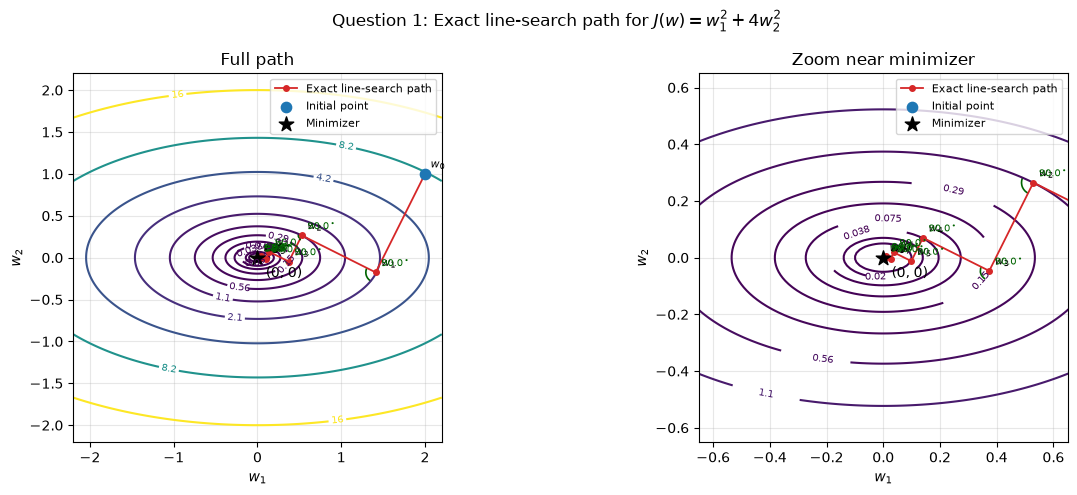

In [3]:
def add_angle_marker(ax, point, incoming, outgoing):
    incoming = np.asarray(incoming, dtype=float)
    outgoing = np.asarray(outgoing, dtype=float)
    incoming_unit = incoming / np.linalg.norm(incoming)
    outgoing_unit = outgoing / np.linalg.norm(outgoing)
    cosine = np.clip(incoming_unit @ outgoing_unit, -1.0, 1.0)
    angle = float(np.degrees(np.arccos(cosine)))
    incoming_angle = float(np.degrees(np.arctan2(incoming[1], incoming[0])))
    outgoing_angle = float(np.degrees(np.arctan2(outgoing[1], outgoing[0])))
    span = (outgoing_angle - incoming_angle) % 360.0
    if span > 180.0:
        incoming_angle, outgoing_angle = outgoing_angle, incoming_angle
    radius = max(0.12 * min(np.linalg.norm(incoming), np.linalg.norm(outgoing)), 0.002)
    arc = Arc(point, 2 * radius, 2 * radius, theta1=incoming_angle,
              theta2=outgoing_angle, color="darkgreen", linewidth=1.2)
    ax.add_patch(arc)
    ax.annotate(rf"{angle:.1f}$^\circ$", point, xytext=(4, 4), textcoords="offset points",
                fontsize=7, color="darkgreen")
    return angle


def draw_q1_path(ax, points, title, xlim=None, ylim=None):
    values = np.linspace(-2.2, 2.2, 400)
    x_grid, y_grid = np.meshgrid(values, values)
    contours = ax.contour(x_grid, y_grid, x_grid**2 + 4 * y_grid**2,
                          levels=np.geomspace(0.01, 16, 12), cmap="viridis")
    ax.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
    ax.plot(points[:, 0], points[:, 1], "o-", color="tab:red", markersize=4,
            linewidth=1.3, label="Exact line-search path")
    ax.scatter(*points[0], color="tab:blue", s=55, zorder=3, label="Initial point")
    ax.scatter(0, 0, color="black", marker="*", s=120, zorder=3, label="Minimizer")
    ax.annotate("(0, 0)", (0, 0), xytext=(6, -14), textcoords="offset points")
    for index, point in enumerate(points):
        ax.annotate(f"$w_{index}$", point, xytext=(4, 4), textcoords="offset points", fontsize=8)
    for index in range(1, len(points) - 1):
        add_angle_marker(ax, points[index], points[index] - points[index - 1], points[index + 1] - points[index])
    ax.set_xlabel("$w_1$")
    ax.set_ylabel("$w_2$")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)
    if xlim is not None:
        ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(fontsize=8)

points_q1 = np.array(iterates_q1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_q1_path(axes[0], points_q1, "Full path")
draw_q1_path(axes[1], points_q1, "Zoom near minimizer", (-0.65, 0.65), (-0.65, 0.65))
fig.suptitle("Question 1: Exact line-search path for $J(w)=w_1^2+4w_2^2$")
fig.tight_layout()
output_dir = Path.cwd() / "assignment2_figures"
output_dir.mkdir(exist_ok=True)
fig.savefig(output_dir / "question1_path.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)


## Question 2: Gradient descent, momentum, and RMSProp

For $J(w_1,w_2)=w_1^2+10w_2^2$,\n\n$$\nabla J(w)=(2w_1,20w_2).$$\n\nFor $g_t=\nabla J(w_t)$, the implemented update rules are:

- **Vanilla gradient descent:** $w_{t+1}=w_t-\alpha g_t$.
- **Momentum:** $v_{t+1}=\beta v_t+g_t$, then $w_{t+1}=w_t-\alpha v_{t+1}$, with $v_0=0$.
- **RMSProp:** $s_{t+1}=\rho s_t+(1-\rho)(g_t\odot g_t)$, then
  $w_{t+1}=w_t-\alpha g_t/(\sqrt{s_{t+1}}+\epsilon)$, with $s_0=0$.


In [4]:
def vanilla_gd(grad_fn, w0, alpha, num_iters):
    w = np.asarray(w0, dtype=float).copy()
    iterates = [w.copy()]
    for _ in range(num_iters):
        w = w - alpha * np.asarray(grad_fn(w), dtype=float)
        iterates.append(w.copy())
    return iterates


def momentum_gd(grad_fn, w0, alpha, beta, num_iters):
    w = np.asarray(w0, dtype=float).copy()
    velocity = np.zeros_like(w)
    iterates = [w.copy()]
    for _ in range(num_iters):
        velocity = beta * velocity + np.asarray(grad_fn(w), dtype=float)
        w = w - alpha * velocity
        iterates.append(w.copy())
    return iterates


def rmsprop_gd(grad_fn, w0, alpha, rho, epsilon, num_iters):
    w = np.asarray(w0, dtype=float).copy()
    squared_gradient_average = np.zeros_like(w)
    iterates = [w.copy()]
    for _ in range(num_iters):
        gradient = np.asarray(grad_fn(w), dtype=float)
        squared_gradient_average = rho * squared_gradient_average + (1 - rho) * gradient * gradient
        w = w - alpha * gradient / (np.sqrt(squared_gradient_average) + epsilon)
        iterates.append(w.copy())
    return iterates


In [5]:
def grad_fn(w):
    return np.array([2.0 * w[0], 20.0 * w[1]])


def loss_fn(w):
    return float(w[0] ** 2 + 10.0 * w[1] ** 2)

q2_w0 = np.array([3.0, 1.0])
alpha = 0.05
beta = 0.9
rho = 0.9
epsilon = 1e-8
all_iterates = {
    "Vanilla GD": vanilla_gd(grad_fn, q2_w0, alpha, 50),
    "Momentum": momentum_gd(grad_fn, q2_w0, alpha, beta, 50),
    "RMSProp": rmsprop_gd(grad_fn, q2_w0, alpha, rho, epsilon, 50),
}

print(f"Parameters: alpha={alpha}, beta={beta}, rho={rho}, epsilon={epsilon}")
for name, iterates in all_iterates.items():
    print(f"{name}: {len(iterates)} iterates ({len(iterates) - 1} updates)")
    print(f"  final J(w_50) = {loss_fn(iterates[-1]):.12g}")
    assert len(iterates) == 51
print("beta=0.9 and rho=0.9 provide moderate smoothing; epsilon=1e-8 prevents division by zero while minimally affecting the update.")


Parameters: alpha=0.05, beta=0.9, rho=0.9, epsilon=1e-08
Vanilla GD: 51 iterates (50 updates)
  final J(w_50) = 0.000239052589988
Momentum: 51 iterates (50 updates)
  final J(w_50) = 0.0646698491083
RMSProp: 51 iterates (50 updates)
  final J(w_50) = 0.323862968054
beta=0.9 and rho=0.9 provide moderate smoothing; epsilon=1e-8 prevents division by zero while minimally affecting the update.


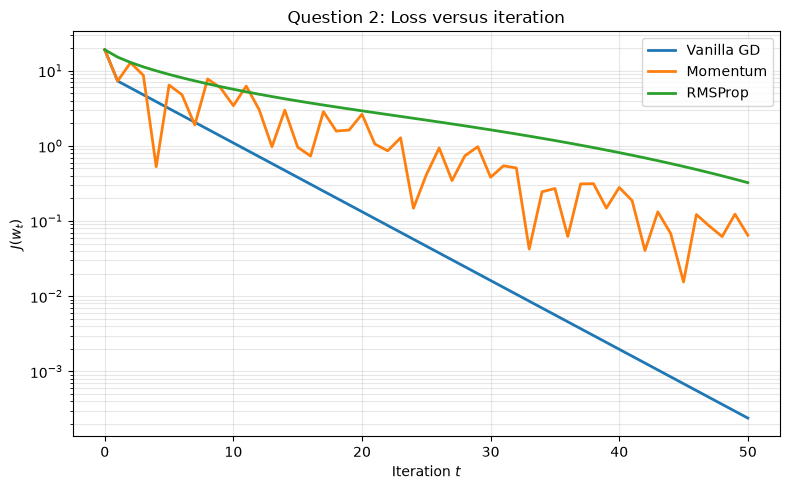

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
loss_floor = 1e-16
for name, iterates in all_iterates.items():
    raw_losses = np.array([loss_fn(w) for w in iterates])
    losses = np.maximum(raw_losses, loss_floor)
    ax.plot(range(len(losses)), losses, linewidth=2, label=name)
ax.set_yscale("log")
ax.set_xlabel("Iteration $t$")
ax.set_ylabel("$J(w_t)$")
ax.set_title("Question 2: Loss versus iteration")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "question2_loss.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)


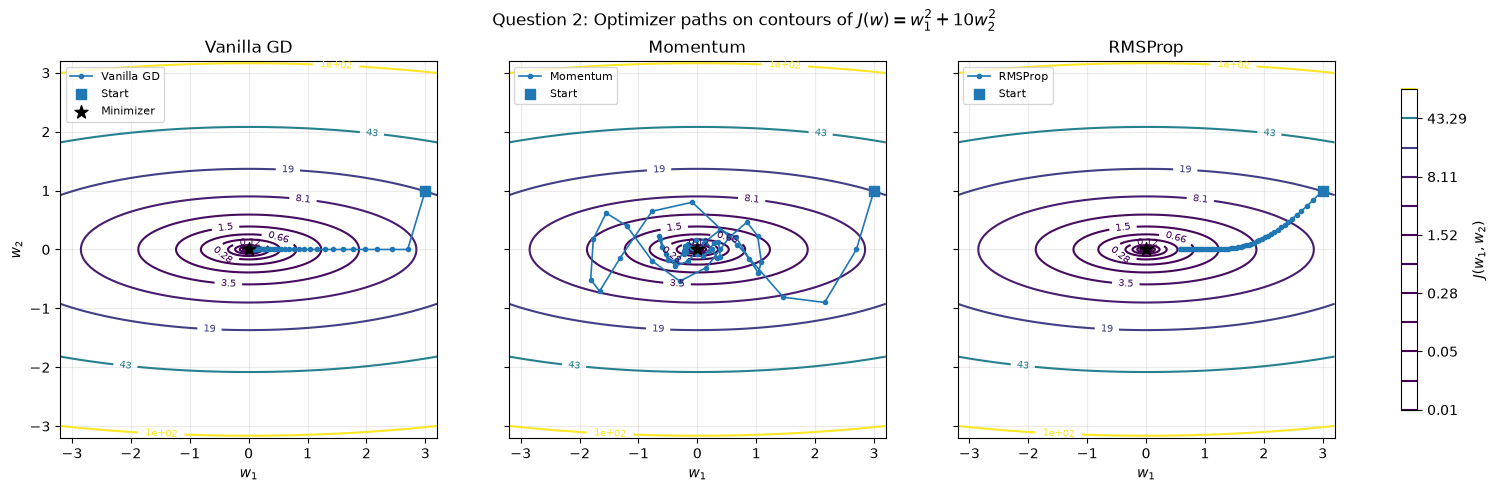

In [7]:
values = np.linspace(-3.2, 3.2, 400)
x_grid, y_grid = np.meshgrid(values, values)
objective_grid = x_grid**2 + 10.0 * y_grid**2
levels = np.geomspace(0.01, 100, 12)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True, constrained_layout=True)
contour_for_colorbar = None
for panel_index, (ax, (name, iterates)) in enumerate(zip(axes, all_iterates.items())):
    contour_for_colorbar = ax.contour(x_grid, y_grid, objective_grid, levels=levels, cmap="viridis")
    ax.clabel(contour_for_colorbar, inline=True, fontsize=7, fmt="%.2g")
    points = np.array(iterates)
    ax.plot(points[:, 0], points[:, 1], "o-", markersize=3, linewidth=1.2, label=name)
    ax.scatter(*points[0], color="tab:blue", marker="s", s=45, zorder=3, label="Start")
    ax.scatter(0, 0, color="black", marker="*", s=95, zorder=3,
               label="Minimizer" if panel_index == 0 else "_nolegend_")
    ax.set_title(name)
    ax.set_xlabel("$w_1$")
    ax.set_xlim(-3.2, 3.2)
    ax.set_ylim(-3.2, 3.2)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("$w_2$")
fig.colorbar(contour_for_colorbar, ax=axes, label="$J(w_1,w_2)$", shrink=0.85)
fig.suptitle("Question 2: Optimizer paths on contours of $J(w)=w_1^2+10w_2^2$")
fig.savefig(output_dir / "question2_paths.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)


### Observations

With $\alpha=0.05$, vanilla gradient descent makes the second coordinate exactly zero after the first update because $1-20\alpha=0$. It then converges slowly along the first coordinate. Momentum oscillates while damping its updates, whereas RMSProp quickly balances the two coordinates but takes nearly constant-size normalized steps and therefore shows a small plateau near the minimizer. The logarithmic loss plot makes these different convergence behaviors visible.

The exact final losses $J(w_{50})$ for all three methods are printed in the preceding cell. With the selected parameters, vanilla GD finishes below momentum at iteration 50 because momentum has an approximate contraction factor of $\sqrt{0.9}\approx0.95$ per step.
